In [ ]:
# ==========================================
# COMMON SETUP — DATA LOADING & PREPROCESSING
# Run this once before any of the three baselines
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings('ignore')

# ── MOUNT DRIVE & AUTO-FIND FILE ──────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

import os
search_root   = '/content/drive/MyDrive'
filename      = 'HF_DATASET.csv'
csv_file_path = None

for root, dirs, files in os.walk(search_root):
    for f in files:
        if f == filename:
            csv_file_path = os.path.join(root, f)
            break
    if csv_file_path:
        break

if csv_file_path is None:
    raise FileNotFoundError(f"'{filename}' not found in Google Drive.")

print(f"File found at: {csv_file_path}")

# ── LOAD & CLEAN DATA ─────────────────────────────────────────────────────────
df_raw = pd.read_csv(csv_file_path, header=None)

df_hdfc           = df_raw.iloc[:, 0:5].copy()
df_hdfc.columns   = ['Date', 'Close', 'Volume', 'High', 'Low']

df_icici          = df_raw.iloc[:, 6:11].copy()
df_icici.columns  = ['Date', 'Close', 'Volume', 'High', 'Low']

for df in [df_hdfc, df_icici]:
    df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
    for col in ['Close', 'Volume', 'High', 'Low']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df.dropna(inplace=True)
    df.set_index('Date', inplace=True)
    df.sort_index(inplace=True)

data = pd.merge(df_hdfc, df_icici, left_index=True, right_index=True, suffixes=('_HDFC', '_ICICI'))
data['Log_HDFC']  = np.log(data['Close_HDFC'])
data['Log_ICICI'] = np.log(data['Close_ICICI'])
data['Spread']    = data['Log_HDFC'] - data['Log_ICICI']

window = 30
data['Z_Score'] = (
    data['Spread'] - data['Spread'].rolling(window).mean()
) / data['Spread'].rolling(window).std()

data.dropna(inplace=True)

# ── TRAIN / TEST SPLIT ────────────────────────────────────────────────────────
split_date = '2023-01-01'
train_data = data[data.index < split_date].copy()
test_data  = data[data.index >= split_date].copy()

train_z = train_data['Z_Score'].values
test_z  = test_data['Z_Score'].values

print(f"Total rows      : {len(data)}")
print(f"Training rows   : {len(train_data)}")
print(f"Testing rows    : {len(test_data)}")
print("Setup complete — ready to run all three baselines.")

Mounted at /content/drive
File found at: /content/drive/MyDrive/Minor_project_dataset/HF_DATASET.csv
Total rows      : 3959
Training rows   : 3197
Testing rows    : 762
Setup complete — ready to run all three baselines.


In [ ]:
# ==========================================
# BASELINE 1: NAÏVE PERSISTENCE MODEL
# Logic: Z_Score(t+1) = Z_Score(t)
# No training required — pure assumption
# ==========================================

# Prediction: every day's prediction = previous day's actual value
naive_actual = test_z[1:]       # actual values from day 2 onwards
naive_pred   = test_z[:-1]      # prediction = yesterday's actual value

print(f"Prediction points: {len(naive_pred)}")
print(f"Sample — Actual: {naive_actual[:5].round(4)}")
print(f"Sample — Pred  : {naive_pred[:5].round(4)}")

Prediction points: 761
Sample — Actual: [1.0537 0.3957 0.9726 1.1715 1.0408]
Sample — Pred  : [0.8192 1.0537 0.3957 0.9726 1.1715]


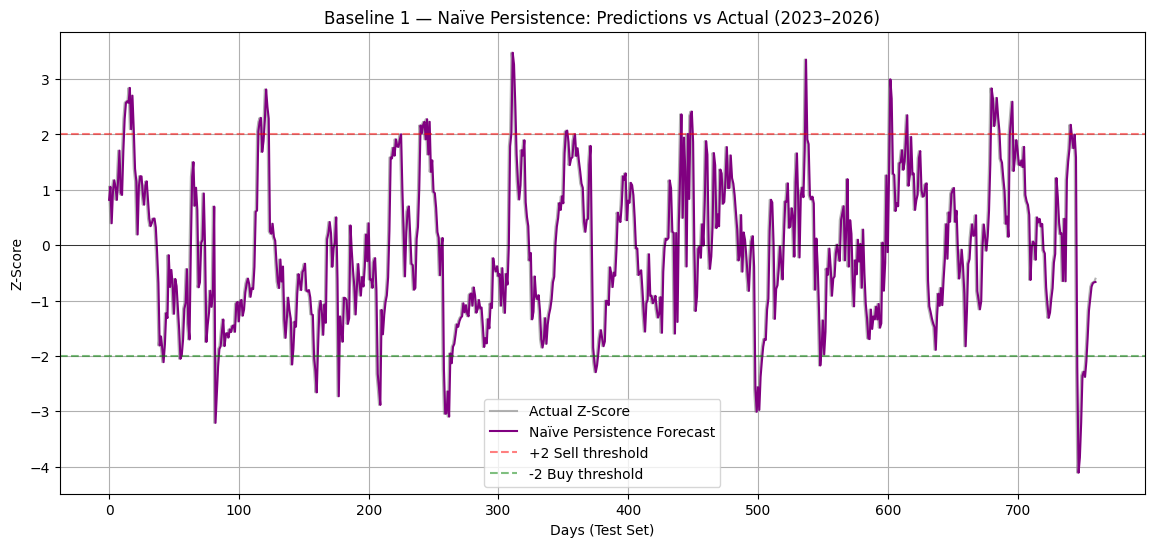

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(naive_actual, label='Actual Z-Score',            color='grey',  alpha=0.6)
plt.plot(naive_pred,   label='Naïve Persistence Forecast', color='purple', linewidth=1.5)
plt.axhline( 2.0, color='red',   linestyle='--', alpha=0.5, label='+2 Sell threshold')
plt.axhline(-2.0, color='green', linestyle='--', alpha=0.5, label='-2 Buy threshold')
plt.axhline( 0,   color='black', linewidth=0.5)
plt.title('Baseline 1 — Naïve Persistence: Predictions vs Actual (2023–2026)')
plt.xlabel('Days (Test Set)')
plt.ylabel('Z-Score')
plt.legend()
plt.grid(True)
plt.show()

NAÏVE PERSISTENCE RESULTS
Initial Capital : ₹100,000
Final Capital   : ₹135,897
Total Return    : 35.90%


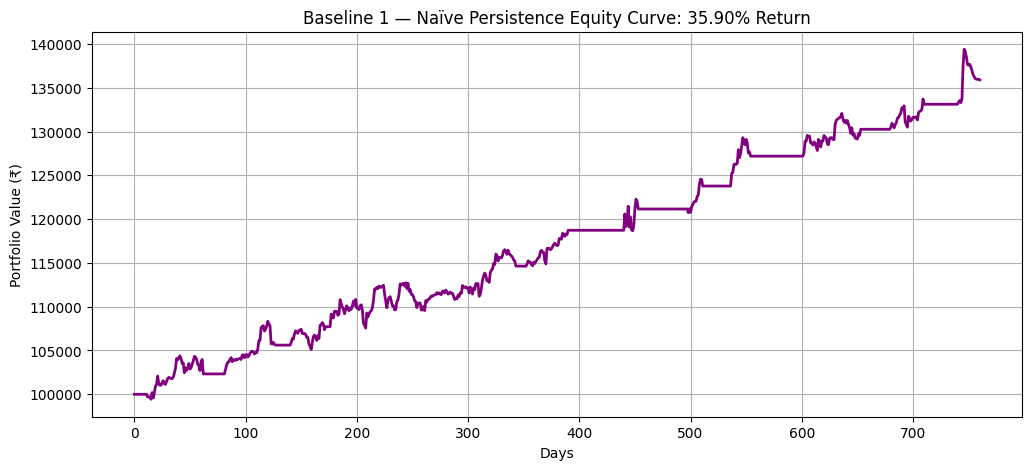

In [ ]:
ENTRY_THRESHOLD = 2.0
initial_capital = 100000
capital         = initial_capital
position        = 0
naive_equity    = []

for i in range(len(naive_pred)):
    z = naive_pred[i]

    if z > ENTRY_THRESHOLD and position == 0:
        position = -1
    elif z < -ENTRY_THRESHOLD and position == 0:
        position = 1
    elif abs(z) < 0.1 and position != 0:
        position = 0

    if i > 0:
        z_change      = naive_actual[i] - naive_actual[i-1]
        daily_profit  = position * z_change * 1000
        capital      += daily_profit

    naive_equity.append(capital)

naive_return = ((capital - initial_capital) / initial_capital) * 100

print(f"=================================")
print(f"NAÏVE PERSISTENCE RESULTS")
print(f"Initial Capital : ₹{initial_capital:,}")
print(f"Final Capital   : ₹{int(capital):,}")
print(f"Total Return    : {naive_return:.2f}%")
print(f"=================================")

plt.figure(figsize=(12, 5))
plt.plot(naive_equity, color='purple', linewidth=2)
plt.title(f'Baseline 1 — Naïve Persistence Equity Curve: {naive_return:.2f}% Return')
plt.xlabel('Days')
plt.ylabel('Portfolio Value (₹)')
plt.grid(True)
plt.show()

In [ ]:
equity_n      = np.array(naive_equity)
daily_ret_n   = (equity_n[1:] - equity_n[:-1]) / (equity_n[:-1] + 1e-9)
sharpe_n      = (np.mean(daily_ret_n) / (np.std(daily_ret_n) + 1e-9)) * np.sqrt(252)
running_max_n = np.maximum.accumulate(equity_n)
max_dd_n      = ((equity_n - running_max_n) / running_max_n).min() * 100
neg_ret_n     = daily_ret_n[daily_ret_n < 0]
sortino_n     = (np.mean(daily_ret_n) / (np.std(neg_ret_n) + 1e-9)) * np.sqrt(252) if len(neg_ret_n) > 0 else 0.0
cagr_n        = ((equity_n[-1] / equity_n[0]) ** (252 / len(equity_n)) - 1) * 100

mse_n  = mean_squared_error(naive_actual, naive_pred)
rmse_n = np.sqrt(mse_n)
mae_n  = mean_absolute_error(naive_actual, naive_pred)
r2_n   = r2_score(naive_actual, naive_pred)

print("=============================================")
print("  BASELINE 1: NAÏVE PERSISTENCE — REPORT CARD")
print("=============================================")
print(f"  Net Profit    : ₹{int(equity_n[-1] - equity_n[0]):,}")
print(f"  Total Return  : {((equity_n[-1]-equity_n[0])/equity_n[0])*100:.2f}%")
print(f"  CAGR          : {cagr_n:.2f}%")
print(f"---------------------------------------------")
print(f"  Sharpe Ratio  : {sharpe_n:.4f}")
print(f"  Sortino Ratio : {sortino_n:.4f}")
print(f"  Max Drawdown  : {max_dd_n:.2f}%")
print(f"---------------------------------------------")
print(f"  MSE           : {mse_n:.5f}")
print(f"  RMSE          : {rmse_n:.5f}")
print(f"  MAE           : {mae_n:.5f}")
print(f"  R² Score      : {r2_n:.4f}")
print("=============================================")

  BASELINE 1: NAÏVE PERSISTENCE — REPORT CARD
  Net Profit    : ₹35,897
  Total Return  : 35.90%
  CAGR          : 10.69%
---------------------------------------------
  Sharpe Ratio  : 1.6423
  Sortino Ratio : 2.0657
  Max Drawdown  : -2.99%
---------------------------------------------
  MSE           : 0.42169
  RMSE          : 0.64938
  MAE           : 0.45485
  R² Score      : 0.7498
